# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

In [1]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [2]:
import datasets
import numpy as np
dataset=datasets.load_dataset("gsri-18/ISEAR-dataset-complete")

In [3]:
dataset

DatasetDict({
    train: Dataset({
        features: ['emotion', 'content', 'Unnamed: 2'],
        num_rows: 7516
    })
})

In [4]:
import numpy as np

class ProbabilisticModel:
    """
    A probability model is able to map input text x to a probability mass function.
    """

    def __call__(self, x: str) -> 'np.array':
        raise NotImplementedError("Concrete implementations will be discussed later")

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class SoftmaxRegressor(ProbabilisticModel):

    def __init__(self, encoder: Encoder):
        self.encoder = encoder

    def __call__(self, x: str) -> 'np.array':
        h = self.encoder(x)
        raise NotImplementedError("We will get there...")

In [5]:

corpus = dataset["train"]["content"]
len(corpus)
vocab_size = 1000
min_frequency = 2

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

#corpus_testing = dataset["test"]["content"]


agnews_outcome_space = part1.clslib.NamedClasses(['anger', 'disgust', 'fear', 'guilt', 'joy', 'sadness', 'shame'])
label_mapping = {name: i for i,name in enumerate(agnews_outcome_space)}
dataset = dataset.map(lambda example: {'emotion': label_mapping[example['emotion']]})


In [6]:
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["content"], dataset["train"]["emotion"])),
            k=num_folds,
            seed=seed
        )
    )

In [7]:
from tokenizers import Tokenizer
from tabulate import tabulate
from collections import OrderedDict

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [8]:
token_indicator_encoder = TokenIndicator(tokenizer)
doc_repr = token_indicator_encoder(corpus[0])

import numpy as np

def similarity(encoder, text1, text2):
    a = encoder(text1)
    b = encoder(text2)

    intersection = np.sum((a == 1) & (b == 1))
    union = np.sum((a == 1) | (b == 1))

    return intersection / union if union else 1.0

In [9]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which me

CPU times: user 6.62 s, sys: 110 ms, total: 6.73 s
Wall time: 6.81 s


In [10]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(self.tokenizer.encode(x).ids)

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] += 1
        return vector

bow_encoder = BagOfWords(tokenizer)

In [11]:
%%time
try:

    #my_classifiers = OrderedDict()

    my_classifiers['logistic_bow-enc'] = []
    for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
        run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
        my_classifiers['logistic_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='logistic',
                save_to=run_folder,
                loglin_args={
                    'max_iter': 100
                }
            )
        )
except ImportError:
    print("You need your own implementation")


  0%|          | 0/5 [00:00<?, ?it/s]

/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which me

CPU times: user 6.69 s, sys: 119 ms, total: 6.81 s
Wall time: 6.85 s


/Users/cristyrussell/Documents/GitHub/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [12]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128,
                'dropout': 0.1,
                'batch_size': 64,
                'learning_rate': 1e-4,
                'weight_decay': 1e-4,
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.997 seconds
Dataloader done! Time taken: 0.036 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/Users/cristyrussell/Documents/GitHub/nlp1-student/part1/smlp.py:118: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/cristyrussell/Documents/GitHub/nlp1-student/part1/smlp.py:121: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.9445 | train acc: 0.1495 | val loss: 1.9366 | val acc: 0.1715
Epoch 02 | train loss: 1.9196 | train acc: 0.2169 | val loss: 1.9200 | val acc: 0.2281
Epoch 03 | train loss: 1.8969 | train acc: 0.2888 | val loss: 1.9007 | val acc: 0.2846
Epoch 04 | train loss: 1.8660 | train acc: 0.3599 | val loss: 1.8760 | val acc: 0.3517
Epoch 05 | train loss: 1.8306 | train acc: 0.4213 | val loss: 1.8446 | val acc: 0.4096
Epoch 06 | train loss: 1.7845 | train acc: 0.4744 | val loss: 1.8060 | val acc: 0.4422
Epoch 07 | train loss: 1.7330 | train acc: 0.5100 | val loss: 1.7628 | val acc: 0.4608
Epoch 08 | train loss: 1.6759 | train acc: 0.5333 | val loss: 1.7165 | val acc: 0.4701
Epoch 09 | train loss: 1.6175 | train acc: 0.5501 | val loss: 1.6695 | val acc: 0.4867
Epoch 10 | train loss: 1.5580 | train acc: 0.5655 | val loss: 1.6252 | val acc: 0.4987
Training done! Time taken: 2.769 seconds
Transforming documents...
Document transformation done! Time taken: 0.997 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9477 | train acc: 0.1495 | val loss: 1.9345 | val acc: 0.1823
Epoch 02 | train loss: 1.9205 | train acc: 0.2192 | val loss: 1.9166 | val acc: 0.2422
Epoch 03 | train loss: 1.8936 | train acc: 0.2979 | val loss: 1.8965 | val acc: 0.2954
Epoch 04 | train loss: 1.8606 | train acc: 0.3680 | val loss: 1.8714 | val acc: 0.3599
Epoch 05 | train loss: 1.8224 | train acc: 0.4269 | val loss: 1.8402 | val acc: 0.3979
Epoch 06 | train loss: 1.7756 | train acc: 0.4663 | val loss: 1.8034 | val acc: 0.4298
Epoch 07 | train loss: 1.7248 | train acc: 0.4991 | val loss: 1.7624 | val acc: 0.4484
Epoch 08 | train loss: 1.6663 | train acc: 0.5260 | val loss: 1.7184 | val acc: 0.4604
Epoch 09 | train loss: 1.6086 | train acc: 0.5433 | val loss: 1.6748 | val acc: 0.4691
Epoch 10 | train loss: 1.5468 | train acc: 0.5550 | val loss: 1.6335 | val acc: 0.4810
Training done! Time taken: 2.106 seconds
Transforming documents...
Document transformation done! Time taken: 0.998 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9455 | train acc: 0.1462 | val loss: 1.9377 | val acc: 0.1610
Epoch 02 | train loss: 1.9212 | train acc: 0.1989 | val loss: 1.9210 | val acc: 0.2056
Epoch 03 | train loss: 1.8965 | train acc: 0.2794 | val loss: 1.9012 | val acc: 0.2655
Epoch 04 | train loss: 1.8671 | train acc: 0.3522 | val loss: 1.8767 | val acc: 0.3333
Epoch 05 | train loss: 1.8314 | train acc: 0.4169 | val loss: 1.8455 | val acc: 0.3772
Epoch 06 | train loss: 1.7875 | train acc: 0.4701 | val loss: 1.8073 | val acc: 0.4192
Epoch 07 | train loss: 1.7349 | train acc: 0.5094 | val loss: 1.7626 | val acc: 0.4405
Epoch 08 | train loss: 1.6763 | train acc: 0.5315 | val loss: 1.7145 | val acc: 0.4617
Epoch 09 | train loss: 1.6185 | train acc: 0.5501 | val loss: 1.6658 | val acc: 0.4804
Epoch 10 | train loss: 1.5588 | train acc: 0.5636 | val loss: 1.6181 | val acc: 0.4963
Training done! Time taken: 2.117 seconds
CPU times: user 15.7 s, sys: 1.36 s, total: 17.1 s
Wall time: 16.3 s


In [13]:
%%time
try:
    #from part1 import solutions
    my_classifiers['mlp_bow-enc'] = []
    for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
        run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
        my_classifiers['mlp_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='mlp',
                save_to=run_folder,
                smlp_args={
                    'hidden_dim': 128,
                    'dropout': 0.1,
                    'batch_size': 64,
                    'learning_rate': 1e-4,
                    'weight_decay': 1e-4,
                    'num_epochs': 10,
                }
            )
        )
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.116 seconds
Dataloader done! Time taken: 0.051 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9370 | train acc: 0.1763 | val loss: 1.9290 | val acc: 0.2028
Epoch 02 | train loss: 1.9085 | train acc: 0.2523 | val loss: 1.9088 | val acc: 0.2507
Epoch 03 | train loss: 1.8785 | train acc: 0.3184 | val loss: 1.8867 | val acc: 0.2866
Epoch 04 | train loss: 1.8452 | train acc: 0.3776 | val loss: 1.8596 | val acc: 0.3358
Epoch 05 | train loss: 1.8071 | train acc: 0.4243 | val loss: 1.8277 | val acc: 0.3797
Epoch 06 | train loss: 1.7625 | train acc: 0.4604 | val loss: 1.7906 | val acc: 0.4122
Epoch 07 | train loss: 1.7110 | train acc: 0.4915 | val loss: 1.7500 | val acc: 0.4255
Epoch 08 | train loss: 1.6580 | train acc: 0.5125 | val loss: 1.7077 | val acc: 0.4402
Epoch 09 | train loss: 1.6020 | train acc: 0.5378 | val loss: 1.6652 | val acc: 0.4581
Epoch 10 | train loss: 1.5474 | train acc: 0.5537 | val loss: 1.6252 | val acc: 0.4807
Training done! Time taken: 2.418 seconds
Transforming documents...
Document transformation done! Time taken: 1.040 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9388 | train acc: 0.1655 | val loss: 1.9267 | val acc: 0.1996
Epoch 02 | train loss: 1.9106 | train acc: 0.2345 | val loss: 1.9082 | val acc: 0.2455
Epoch 03 | train loss: 1.8839 | train acc: 0.2897 | val loss: 1.8859 | val acc: 0.2888
Epoch 04 | train loss: 1.8512 | train acc: 0.3506 | val loss: 1.8592 | val acc: 0.3287
Epoch 05 | train loss: 1.8136 | train acc: 0.4089 | val loss: 1.8261 | val acc: 0.3766
Epoch 06 | train loss: 1.7683 | train acc: 0.4472 | val loss: 1.7869 | val acc: 0.4138
Epoch 07 | train loss: 1.7180 | train acc: 0.4805 | val loss: 1.7434 | val acc: 0.4331
Epoch 08 | train loss: 1.6633 | train acc: 0.5131 | val loss: 1.7001 | val acc: 0.4458
Epoch 09 | train loss: 1.6065 | train acc: 0.5297 | val loss: 1.6550 | val acc: 0.4651
Epoch 10 | train loss: 1.5485 | train acc: 0.5476 | val loss: 1.6146 | val acc: 0.4704
Training done! Time taken: 2.209 seconds
Transforming documents...
Document transformation done! Time taken: 1.030 seconds
Dataloa

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9456 | train acc: 0.1633 | val loss: 1.9289 | val acc: 0.1963
Epoch 02 | train loss: 1.9172 | train acc: 0.2263 | val loss: 1.9102 | val acc: 0.2402
Epoch 03 | train loss: 1.8899 | train acc: 0.2909 | val loss: 1.8886 | val acc: 0.2908
Epoch 04 | train loss: 1.8567 | train acc: 0.3514 | val loss: 1.8629 | val acc: 0.3340
Epoch 05 | train loss: 1.8212 | train acc: 0.4078 | val loss: 1.8323 | val acc: 0.3673
Epoch 06 | train loss: 1.7760 | train acc: 0.4390 | val loss: 1.7966 | val acc: 0.4065
Epoch 07 | train loss: 1.7255 | train acc: 0.4879 | val loss: 1.7569 | val acc: 0.4371
Epoch 08 | train loss: 1.6716 | train acc: 0.5069 | val loss: 1.7151 | val acc: 0.4491
Epoch 09 | train loss: 1.6144 | train acc: 0.5280 | val loss: 1.6729 | val acc: 0.4697
Epoch 10 | train loss: 1.5566 | train acc: 0.5498 | val loss: 1.6329 | val acc: 0.4790
Training done! Time taken: 2.048 seconds
Transforming documents...
Document transformation done! Time taken: 1.007 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9423 | train acc: 0.1522 | val loss: 1.9268 | val acc: 0.1796
Epoch 02 | train loss: 1.9138 | train acc: 0.2124 | val loss: 1.9065 | val acc: 0.2335
Epoch 03 | train loss: 1.8874 | train acc: 0.2929 | val loss: 1.8845 | val acc: 0.2967
Epoch 04 | train loss: 1.8565 | train acc: 0.3625 | val loss: 1.8577 | val acc: 0.3679
Epoch 05 | train loss: 1.8181 | train acc: 0.4189 | val loss: 1.8253 | val acc: 0.4085
Epoch 06 | train loss: 1.7745 | train acc: 0.4648 | val loss: 1.7860 | val acc: 0.4431
Epoch 07 | train loss: 1.7254 | train acc: 0.4971 | val loss: 1.7442 | val acc: 0.4617
Epoch 08 | train loss: 1.6709 | train acc: 0.5152 | val loss: 1.7001 | val acc: 0.4711
Epoch 09 | train loss: 1.6155 | train acc: 0.5290 | val loss: 1.6543 | val acc: 0.4810
Epoch 10 | train loss: 1.5575 | train acc: 0.5501 | val loss: 1.6110 | val acc: 0.4877
Training done! Time taken: 2.070 seconds
CPU times: user 15.7 s, sys: 1.44 s, total: 17.1 s
Wall time: 16.4 s


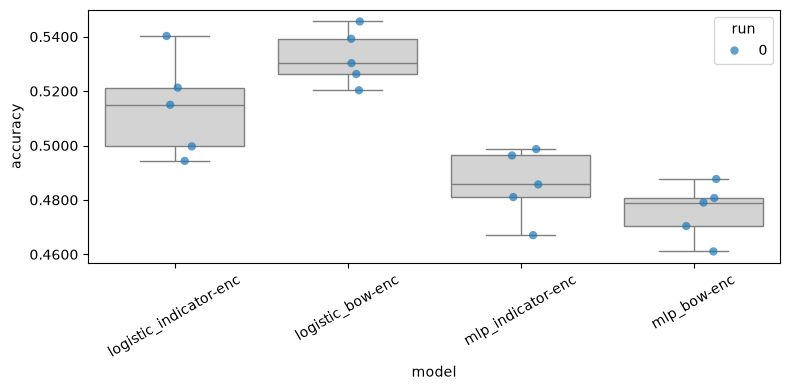

In [14]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

# Additionals


### Tokenizer - cap tokenizer


In [15]:
class CapTokenizer(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""

        unique_token_ids = list(self.tokenizer.encode(x).ids)
        if len(unique_token_ids) - len(self) < 0:
            vector = unique_token_ids[:len(self)] + [0] * (len(self) - len(unique_token_ids))
        else:
            vector = unique_token_ids[:len(self)]
        return vector

cap_encoder = CapTokenizer(tokenizer)


1000
167
